In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import time
import datetime
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import randint
from os import listdir
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, array_to_img, load_img
from tensorflow.keras import layers
from numpy import asarray, savez_compressed
from tensorflow.keras import Input
from numpy import load, zeros, ones
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.initializers import RandomNormal
from tensorflow.keras.layers import Conv2D, UpSampling2D, Activation, Dense, Reshape, Flatten, MaxPooling2D
from tensorflow.keras.layers import Concatenate, Dropout, BatchNormalization, LeakyReLU, Conv2DTranspose, ReLU, GlobalAveragePooling2D
from tensorflow.keras import backend as K
from sklearn.model_selection import train_test_split
from sklearn.model_selection import ParameterGrid
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from keras.models import Sequential
from tensorflow.keras.losses import MeanSquaredError, BinaryCrossentropy
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

In [ ]:
K.clear_session()

In [ ]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
# physical_devices = tf.config.list_physical_devices('GPU')
# tf.config.experimental.set_memory_growth(physical_devices[0], True)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
  # Restrict TensorFlow to only allocate 39GB of memory on the first GPU
  try:
    tf.config.set_logical_device_configuration(
        gpus[0],
        [tf.config.LogicalDeviceConfiguration(memory_limit=39936)])
    logical_gpus = tf.config.list_logical_devices('GPU')
    print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
  except RuntimeError as e:
    # Virtual devices must be set before GPUs have been initialized
    print(e)

Num GPUs Available:  0


In [ ]:
# Function to load and preprocess images
def load_and_preprocess_images(data_path, folder):
    images = []
    folder_path = os.path.join(data_path, folder)

    # Sort the filenames to ensure consistent order
    filenames = sorted(os.listdir(folder_path))

    for filename in sorted(os.listdir(folder_path)):
        img_path = os.path.join(folder_path, filename)
        img = load_img(img_path, target_size=(400, 600))  # Resize images as needed
        img_array = img_to_array(img) / 255.0  # Normalize pixel values to the range [0, 1]
        images.append(img_array)

    return np.array(images)

data_path = '/content/drive/MyDrive/LOL_dataset/lol_dataset/'

train_low_light_images, val_low_light_images = train_test_split(load_and_preprocess_images(data_path, 'our485/low'), test_size=0.2, random_state=42)
train_normal_light_images, val_normal_light_images = train_test_split(load_and_preprocess_images(data_path, 'our485/high'), test_size=0.2, random_state=42)

test_low_light_images = load_and_preprocess_images(data_path, 'eval15/low')
test_normal_light_images = load_and_preprocess_images(data_path, 'eval15/high')


In [ ]:
# Print shapes of the split datasets
print("Shape of train_images:", train_low_light_images.shape)
print("Shape of val_images:", val_low_light_images.shape)
print("Shape of test_images:", test_low_light_images.shape)

Shape of train_images: (388, 400, 600, 3)
Shape of val_images: (97, 400, 600, 3)
Shape of test_images: (15, 400, 600, 3)


In [ ]:
input_shape=((400, 600, 3))

In [ ]:
def generated_cnn_model_images(enhanced_images):
  # Visualize a few enhanced images
  num_visualize = 3
  for i in range(num_visualize):
      plt.figure(figsize=(12, 6))

      plt.subplot(1, 3, 1)
      plt.imshow(test_low_light_images[i])
      plt.title('Low Light Image')

      plt.subplot(1, 3, 2)
      plt.imshow(enhanced_images[i])
      plt.title('Enhanced Image')

      plt.subplot(1, 3, 3)
      plt.imshow(test_normal_light_images[i])
      plt.title('Ground Truth (Normal Light)')

      plt.show()

In [ ]:
# Model 4: Feed-Forward Denoising CNN with Filtering Stages
# Islam MT, Rahman SMM, Ahmad MO, Swamy MNS (2018) Mixed Gaussian-impulse noise reduction from images using convolutional neural network.

def build_ffd_cnn_denoising_model():
    model = Sequential()

    # Pre-processing stage
    model.add(Conv2D(64, kernel_size=3, strides=1, padding='same', input_shape=input_shape))
    model.add(BatchNormalization())
    model.add(ReLU())

    # Four convolution filtering stages
    for _ in range(4):
        model.add(Conv2D(64, kernel_size=3, strides=1, padding='same'))
        model.add(BatchNormalization())
        model.add(ReLU())
        model.add(MaxPooling2D(pool_size=2, strides=2, padding='same'))
        model.add(UpSampling2D(size=(2, 2)))

    # Global Average Pooling
    model.add(GlobalAveragePooling2D())

    # Fully connected layer
    model.add(Dense(256, activation='relu'))

    # Output layer
    model.add(Dense(np.prod(input_shape), activation='sigmoid'))
    model.add(Reshape(input_shape))

    return model


In [ ]:
# Compile CNN model
def ffd_cnn_model_compile(params):
  # Build the feed-forward denoising model
  denoising_model = build_ffd_cnn_denoising_model()
  # Compile the model
  denoising_model.compile(optimizer=Adam(learning_rate=params['learning_rate']), loss='mse', metrics='accuracy')
  checkpoint_basic_cnn = ModelCheckpoint("/content/drive/MyDrive/ffd_cnn_denoising_model.h5", save_best_only=True)
  # early_stopping_basic_cnn = EarlyStopping(patience=5, restore_best_weights=True)
  # Train the model
  history = denoising_model.fit(
      train_low_light_images, train_normal_light_images,  # Denoising autoencoder, input and output are the same
      epochs=params['epochs'],
      batch_size=params['batch_size'],
      validation_data=(val_low_light_images, val_normal_light_images),
      callbacks=[checkpoint_basic_cnn]
  )
  # Evaluate the model on the test set
  test_loss = denoising_model.evaluate(test_low_light_images, test_normal_light_images)

  enhanced_images = denoising_model.predict(test_low_light_images)
  generated_cnn_model_images(enhanced_images)

  return denoising_model

In [ ]:
# Function to evaluate the model with different hyperparameter combinations
def evaluate_ffd_cnn_model_(train_images, val_images, params):
    # Build the denoising model
    ffd_cnn_model = ffd_cnn_model_compile(params)

    # Evaluate on validation set
    denoised_images = ffd_cnn_model.predict(val_images)

    mse = MeanSquaredError()(val_images, denoised_images).numpy()
    psnr = peak_signal_noise_ratio(val_images[0], denoised_images[0], data_range=denoised_images[0].max())
    ssim_index = structural_similarity(val_images[0], denoised_images[0], multichannel=True)

    return {'params': params, 'mse': mse, 'psnr': psnr, 'ssim': ssim_index}

In [ ]:
param_grid = {
    'learning_rate': [0.0001, 0.001, 0.01],
    'epochs': [50],
    'batch_size': [8]
}

# Generate all combinations of hyperparameters
param_combinations = list(ParameterGrid(param_grid))

# Example: Evaluate the model with different hyperparameter combinations
for params in param_combinations:
    results = evaluate_ffd_cnn_model_(train_low_light_images, val_low_light_images, params)
    print(f"Hyperparameters: {results['params']}, MSE: {results['mse']}, PSNR: {results['psnr']}, SSIM: {results['ssim']}")

Epoch 1/50


In [ ]:
K.clear_session()

In [ ]:
# GAN Model

In [ ]:
def build_generator(input_shape, generator_activation):
    inputs = tf.keras.Input(shape=input_shape)

    # Encoder
    x = layers.Conv2D(64, (3, 3), padding='same', activation= generator_activation)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, (3, 3), padding='same', activation=generator_activation)(x)
    x = layers.BatchNormalization()(x)

    # Bottleneck - Residual Blocks with Batch Normalization
    for _ in range(6):
        x = residual_block(x, 128, generator_activation)

    # Decoder
    x = layers.Conv2D(64, (3, 3), padding='same', activation=generator_activation)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(3, (3, 3), padding='same', activation='sigmoid')(x)

    outputs = layers.Add()([x, inputs])

    generator = tf.keras.Model(inputs, outputs, name='generator')
    return generator

# Define the discriminator model
def build_discriminator(input_shape, discriminator_activation):
    inputs = tf.keras.Input(shape=input_shape)

    x = layers.Conv2D(64, (3, 3), padding='same', activation=discriminator_activation)(inputs)
    x = layers.Conv2D(128, (3, 3), padding='same', activation=discriminator_activation)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(1, activation='sigmoid')(x)

    discriminator = tf.keras.Model(inputs, x, name='discriminator')
    return discriminator

# Define a residual block
def residual_block(x, filters, generator_activation):
    shortcut = x

    x = layers.Conv2D(filters, (3, 3), padding='same', activation=generator_activation)(x)
    x = layers.Conv2D(filters, (3, 3), padding='same')(x)

    x = layers.Add()([x, shortcut])  # Skip connection
    x = layers.Activation(generator_activation)(x)

    return x

input_shape = (400, 600, 3)

In [ ]:
def save_generated_images(low_light_images, high_light_images, generated_images, epoch):
    num_images = len(low_light_images)
    min_length = min(len(low_light_images), len(high_light_images), len(generated_images))

    print(f"Num Images: {num_images}")
    print(f"Min Length: {min_length}")

    for i in range(min_length):
        low_light = low_light_images[i]
        high_light = high_light_images[i]
        generated = (generated_images[i] * 255).astype(np.uint8)

        print(f"Index: {i}")

        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.imshow(low_light)
        plt.title('Low-Light Image')
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(high_light)
        plt.title('High-Light Image')
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.imshow(generated)
        plt.title('Generated Image')
        plt.axis('off')
        plt.show()

In [ ]:
# Function to build the GAN model
from tensorflow.keras.models import load_model

def build_gan(learning_rate, generator_activation, discriminator_activation):

# Load the saved model
  denoised_model = load_model("/content/drive/MyDrive/ffd_cnn_denoising_model.h5")
  # Build the generator (use the denoising CNN as the generator)
  generator = denoised_model
  generator.trainable = False  # Freeze the denoising CNN during GAN training
  # generator = build_generator(input_shape, generator_activation)

  discriminator = build_discriminator(input_shape, discriminator_activation)
  discriminator.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=learning_rate, beta_1=0.5), metrics=['accuracy'])

  # Compile the GAN
  discriminator.trainable = False
  gan_input = tf.keras.Input(shape=(400, 600, 3))

  # Generate denoised images using the denoising CNN (generator)
  x_denoised = denoised_model(gan_input)
  # Generate enhanced images using the GAN's generator
  x_enhanced = generator(x_denoised)

  # x = generator(gan_input)
  gan_output = discriminator(x_enhanced)

  gan = Model(gan_input, gan_output)
  gan.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=learning_rate, beta_1=0.5))
  # test_loss = gan.evaluate(test_low_light_images, test_normal_light_images)
  # print("Test Loss: ", test_loss)

  return gan, generator, discriminator

In [ ]:
def train_gan(gan, x_train_low, x_train_high, epochs, batch_size, generator, discriminator):
  # Train the GAN
  for epoch in range(epochs):
      for _ in range(len(x_train_low) // batch_size):
          # Sample a batch of low-light images
          idx = np.random.randint(0, len(x_train_low), batch_size)
          low_batch = x_train_low[idx]

          # Generate corresponding high-light images using the generator
          generated_high_batch = generator.predict(low_batch)

          # Create labels for real and generated images
          real_labels = np.ones((batch_size, 1))
          fake_labels = np.zeros((batch_size, 1))

          # Train the discriminator on real images
          d_loss_real = discriminator.train_on_batch(x_train_high[idx], real_labels)

          # Train the discriminator on generated images
          d_loss_fake = discriminator.train_on_batch(generated_high_batch, fake_labels)

          # Compute the total discriminator loss
          d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

          # Train the generator to fool the discriminator
          g_loss = gan.train_on_batch(low_batch, real_labels)

          print(f"Epoch {epoch + 1}/{epochs} [D loss: {d_loss[0]} | D accuracy: {100 * d_loss[1]}] [G loss: {g_loss}]")

      if (epoch + 1) % 50 == 0:
        generated_images = generator.predict(val_low_light_images[:4])
        # Ensure the correct mapping of generated images to low and high images
        mapped_generated_images = generated_images[:len(val_low_light_images[:15])]

        # Now you can use the save_generated_images function to save and display the comparison
        print("x_val_low: ",len(val_low_light_images[:15]))
        save_generated_images(val_low_light_images[:15], val_normal_light_images[:15], mapped_generated_images, epoch + 1)

In [ ]:
# Function to evaluate the GAN model with different hyperparameter combinations
def evaluate_gan_model(x_train_low, x_train_high, x_val_low, x_val_high, params):
    # latent_dim = params['latent_dim']
    learning_rate = params['learning_rate']
    generator_activation = params['generator_activation']
    discriminator_activation = params['discriminator_activation']
    epochs = params['epochs']
    batch_size = params['batch_size']

    # Build the GAN model
    gan, generator, discriminator = build_gan(learning_rate, generator_activation, discriminator_activation)

    # Train the GAN model
    train_gan(gan, x_train_low, x_train_high, epochs, batch_size, generator, discriminator)

    # Generate images using the trained GAN
    generated_images = generator.predict(x_val_low)

    # Evaluate generated images (replace this with your evaluation metrics)
    mse = np.mean(np.square(x_val_high - generated_images))
    psnr = peak_signal_noise_ratio(x_val_high[0], generated_images[0], data_range=generated_images[0].max())
    ssim_index = structural_similarity(x_val_high[0], generated_images[0], multichannel=True)

    return {'params': params, 'mse': mse, 'psnr': psnr, 'ssim': ssim_index}

1/1 [==============================] - 0s 172ms/step
Epoch 1/50 [D loss: 18205.133551597595 | D accuracy: 25.0] [G loss: 72.42453002929688]
1/1 [==============================] - 0s 30ms/step
Epoch 1/50 [D loss: 1659.0879364013672 | D accuracy: 0.0] [G loss: 17.03289031982422]
1/1 [==============================] - 0s 29ms/step
Epoch 1/50 [D loss: 17.84334033727646 | D accuracy: 50.0] [G loss: 2.444619655609131]
1/1 [==============================] - 0s 30ms/step
Epoch 1/50 [D loss: 1.2851746082305908 | D accuracy: 43.75] [G loss: 0.031184092164039612]
1/1 [==============================] - 0s 29ms/step
Epoch 1/50 [D loss: 68.49007147550583 | D accuracy: 6.25] [G loss: 13.336206436157227]
1/1 [==============================] - 0s 29ms/step
Epoch 1/50 [D loss: 2.500145822763443 | D accuracy: 50.0] [G loss: 0.8071504235267639]
1/1 [==============================] - 0s 29ms/step
Epoch 1/50 [D loss: 0.9003369212150574 | D accuracy: 50.0] [G loss: 0.7339849472045898]
1/1 [==================

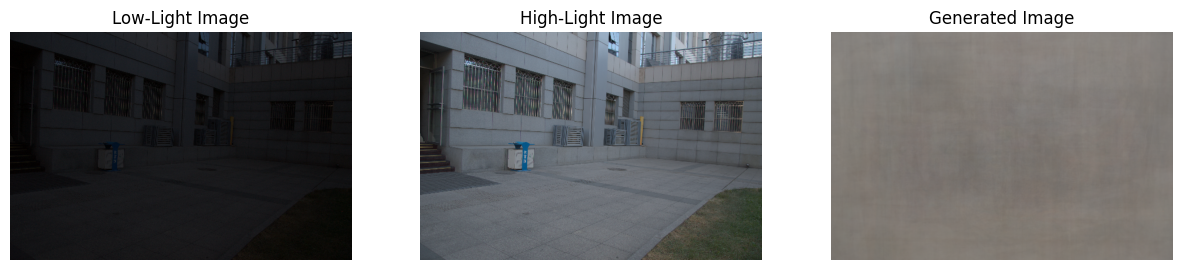

Index: 1


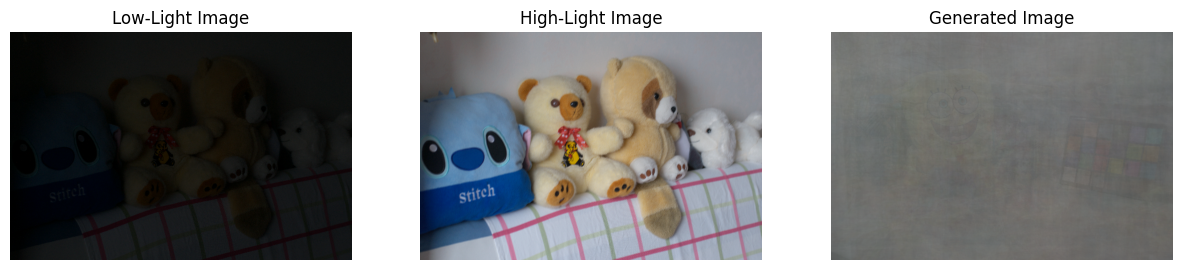

Index: 2


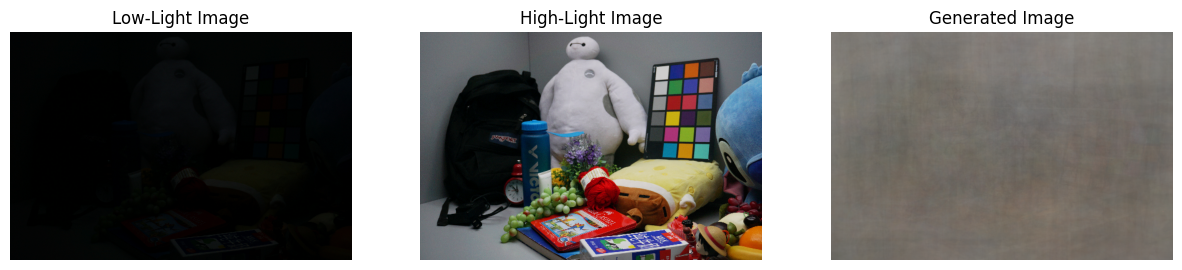

Index: 3


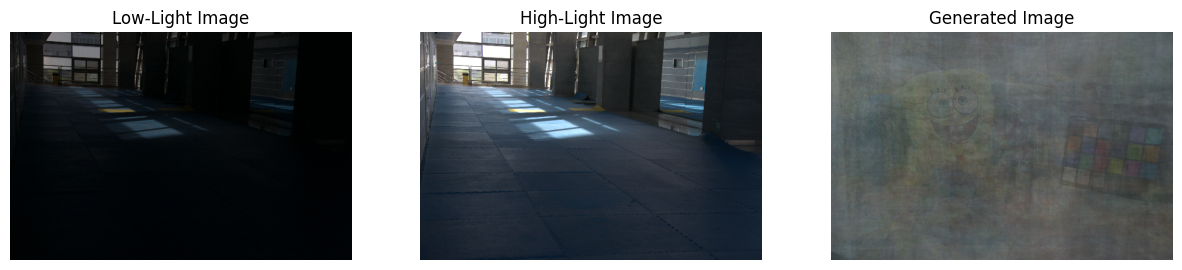

4/4 [==============================] - 0s 124ms/step


<ipython-input-31-adc92e26991a>:22: FutureWarning: `multichannel` is a deprecated argument name for `structural_similarity`. It will be removed in version 1.0. Please use `channel_axis` instead.
  ssim_index = structural_similarity(x_val_high[0], generated_images[0], multichannel=True)


Hyperparameters: {'batch_size': 8, 'discriminator_activation': 'relu', 'epochs': 50, 'generator_activation': 'relu', 'learning_rate': 0.01}, MSE: 0.04705159738659859, PSNR: 12.215393802978898, SSIM: 0.7159510254859924
1/1 [==============================] - 0s 164ms/step
Epoch 1/50 [D loss: 289.5375963449478 | D accuracy: 0.0] [G loss: 6.75902566098695e-33]
1/1 [==============================] - 0s 30ms/step
Epoch 1/50 [D loss: 1.9426567554473877 | D accuracy: 50.0] [G loss: 88.83091735839844]
1/1 [==============================] - 0s 29ms/step
Epoch 1/50 [D loss: 86.07127380371094 | D accuracy: 50.0] [G loss: 19.5004825592041]
1/1 [==============================] - 0s 29ms/step
Epoch 1/50 [D loss: 47.63501739501953 | D accuracy: 0.0] [G loss: 0.0003760326944757253]
1/1 [==============================] - 0s 29ms/step
Epoch 1/50 [D loss: 7.823399513959885 | D accuracy: 50.0] [G loss: 0.5376176238059998]
1/1 [==============================] - 0s 37ms/step
Epoch 1/50 [D loss: 6.34667181968

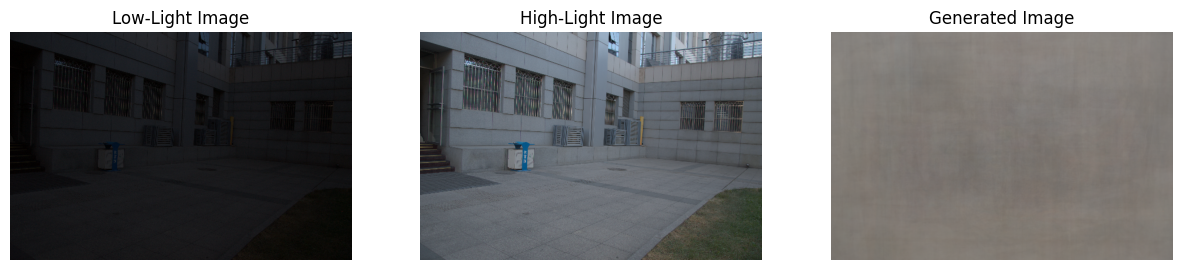

Index: 1


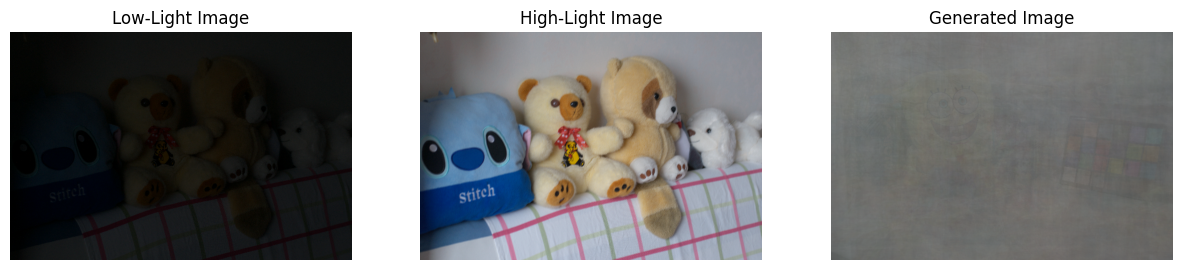

Index: 2


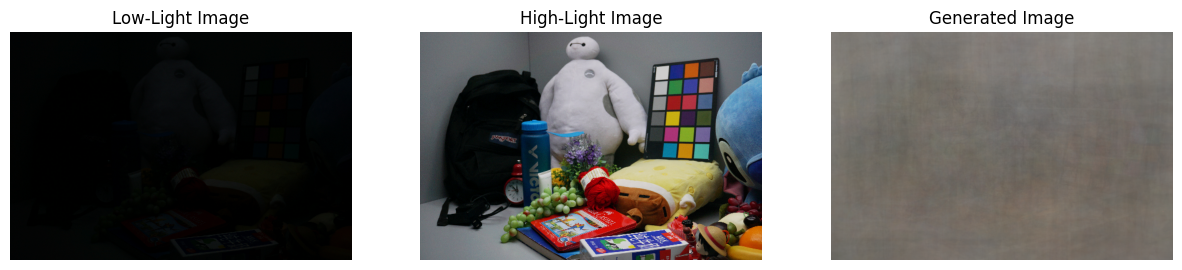

Index: 3


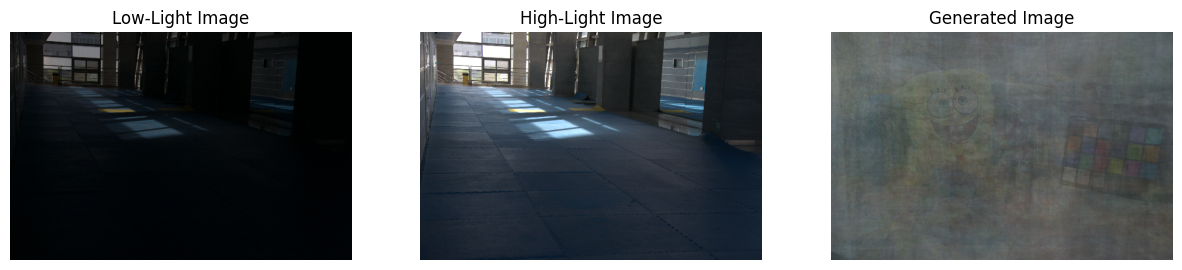

4/4 [==============================] - 0s 127ms/step
Hyperparameters: {'batch_size': 8, 'discriminator_activation': 'relu', 'epochs': 50, 'generator_activation': 'relu', 'learning_rate': 0.001}, MSE: 0.04705159738659859, PSNR: 12.215393802978898, SSIM: 0.7159510254859924
1/1 [==============================] - 0s 164ms/step
Epoch 1/50 [D loss: 57.71623635292053 | D accuracy: 6.25] [G loss: 3.818529173416074e-11]
1/1 [==============================] - 0s 30ms/step
Epoch 1/50 [D loss: 0.3698988854885284 | D accuracy: 50.0] [G loss: 36.83263397216797]
1/1 [==============================] - 0s 29ms/step
Epoch 1/50 [D loss: 33.338352883580114 | D accuracy: 50.0] [G loss: 0.004572954494506121]
1/1 [==============================] - 0s 29ms/step
Epoch 1/50 [D loss: 9.207052690442652 | D accuracy: 50.0] [G loss: 27.043964385986328]
1/1 [==============================] - 0s 29ms/step
Epoch 1/50 [D loss: 20.981723289659158 | D accuracy: 50.0] [G loss: 0.14023111760616302]
1/1 [===================

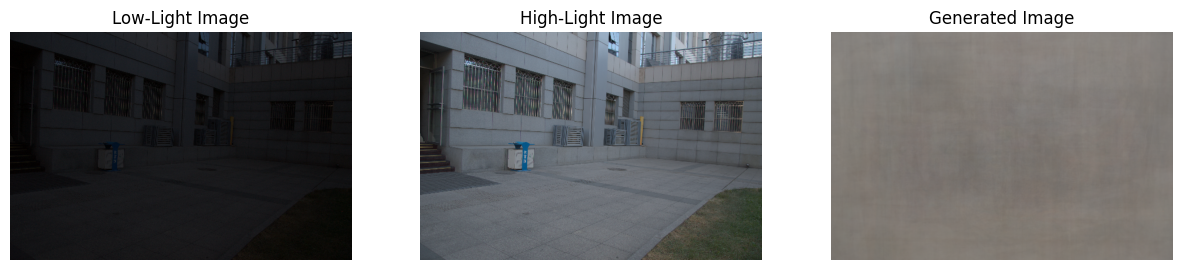

Index: 1


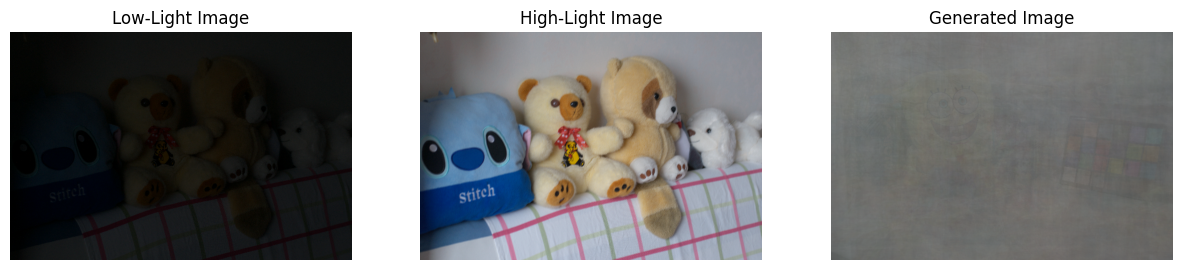

Index: 2


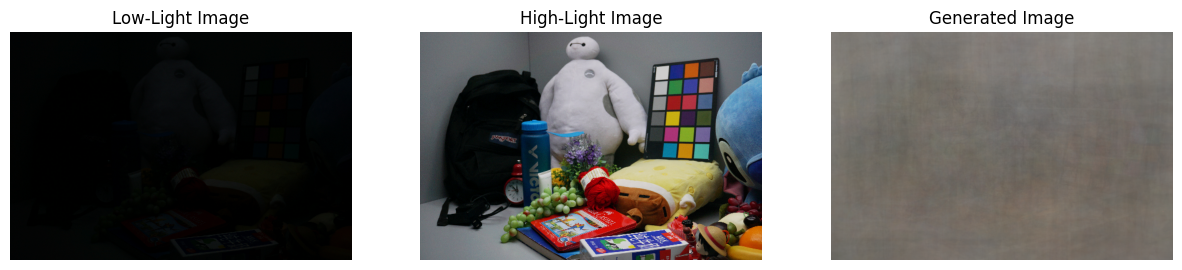

Index: 3


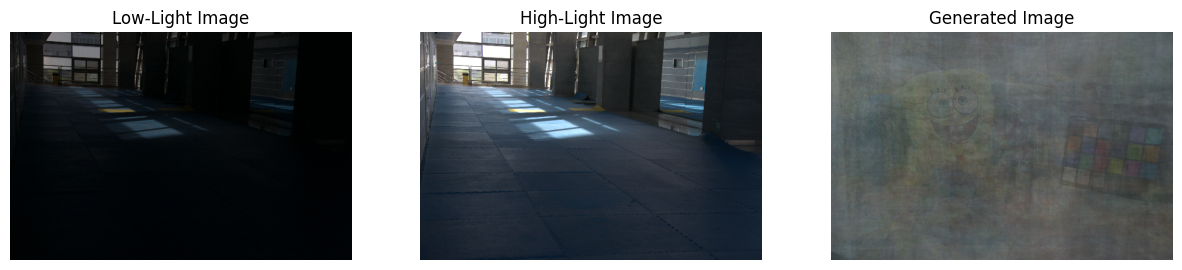

4/4 [==============================] - 0s 123ms/step
Hyperparameters: {'batch_size': 8, 'discriminator_activation': 'relu', 'epochs': 50, 'generator_activation': 'relu', 'learning_rate': 0.0001}, MSE: 0.04705159738659859, PSNR: 12.215393802978898, SSIM: 0.7159510254859924


In [ ]:
from keras.layers import ReLU, GlobalAveragePooling2D
# Specify the hyperparameter grid for search
param_grid = {
    'learning_rate': [0.01, 0.001, 0.0001],
    'epochs': [50],
    'batch_size': [8],
    'generator_activation': ['relu'],
    'discriminator_activation': ['relu']
}

# Generate all combinations of hyperparameters
param_combinations = list(ParameterGrid(param_grid))

# Example: Evaluate the GAN model with different hyperparameter combinations
for params in param_combinations:
    results = evaluate_gan_model(train_low_light_images, train_normal_light_images, val_low_light_images, val_normal_light_images, params)
    print(f"Hyperparameters: {results['params']}, MSE: {results['mse']}, PSNR: {results['psnr']}, SSIM: {results['ssim']}")